# Water Quality Prediction — Model Training

This notebook trains and compares multiple ML classifiers to predict water quality
(**Good / Moderate / Poor**) from four sensor readings: **pH, temperature, turbidity, TDS**.

It reproduces the pipeline behind the artifacts used by the Flask app (`app.py`):
- `models/best_water_quality_model.pkl`
- `models/scaler.pkl`
- `models/label_encoder.pkl`
- `models/feature_order.pkl`

**Dataset:** `aquatic_pollution_dataset.csv`

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

sns.set_style("whitegrid")
%matplotlib inline

In [2]:
DATA_PATH = "aquatic_pollution_dataset.csv"
MODELS_DIR = "models"
PLOTS_DIR = "plots"

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(PLOTS_DIR, exist_ok=True)

RANDOM_STATE = 42
FEATURE_ORDER = ["pH", "temperature", "turbidity", "TDS"]
TARGET_COL = "water_quality"


## 1. Load the Dataset

In [3]:
df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape}")
df.head()

Shape: (5000, 5)


,pH,temperature,turbidity,TDS,water_quality
0,7.16,12.40,2089,135.00,Moderate
1,5.32,22.52,2858,817.12,Poor
2,5.24,34.37,58,250.42,Moderate
3,6.58,24.79,3674,429.66,Moderate
4,9.45,17.97,973,920.64,Poor


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   pH             5000 non-null   float64
 1   temperature    5000 non-null   float64
 2   turbidity      5000 non-null   int64  
 3   TDS            5000 non-null   float64
 4   water_quality  5000 non-null   str    
dtypes: float64(3), int64(1), str(1)
memory usage: 195.4 KB


In [5]:
df[TARGET_COL].value_counts()

water_quality
Moderate    2741
Poor        1725
Good         534
Name: count, dtype: int64

## 2. Exploratory Data Analysis

Each plot below is also saved to `plots/` with the same filenames used in the project.

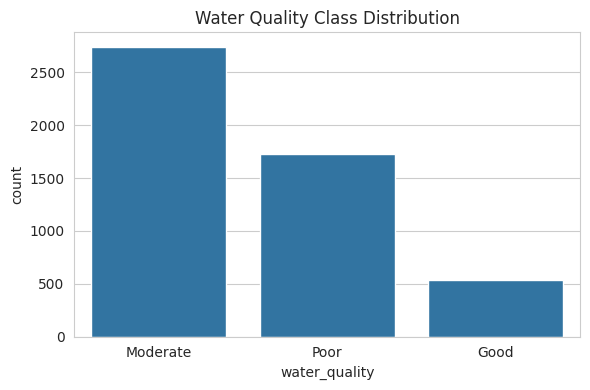

In [6]:
# 01 - class distribution
plt.figure(figsize=(6, 4))
sns.countplot(x=TARGET_COL, data=df, order=df[TARGET_COL].value_counts().index)
plt.title("Water Quality Class Distribution")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/01_class_distribution.png", dpi=150)
plt.show()

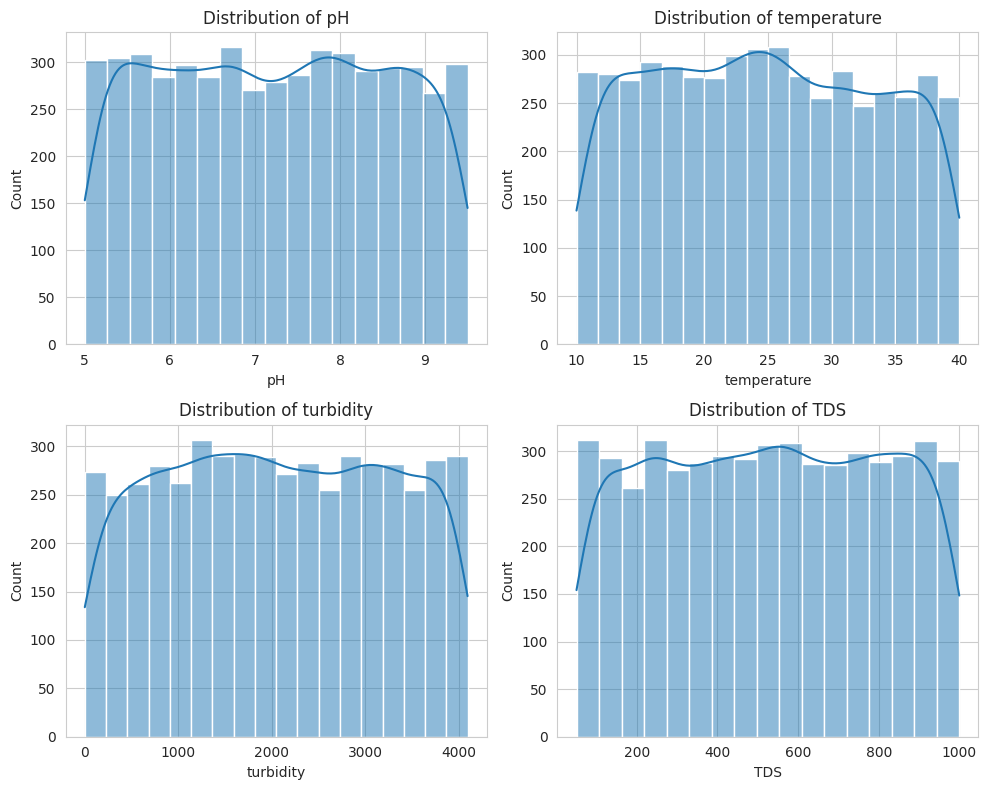

In [7]:
# 02 - feature distributions
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, col in zip(axes.flatten(), FEATURE_ORDER):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/02_feature_distributions.png", dpi=150)
plt.show()

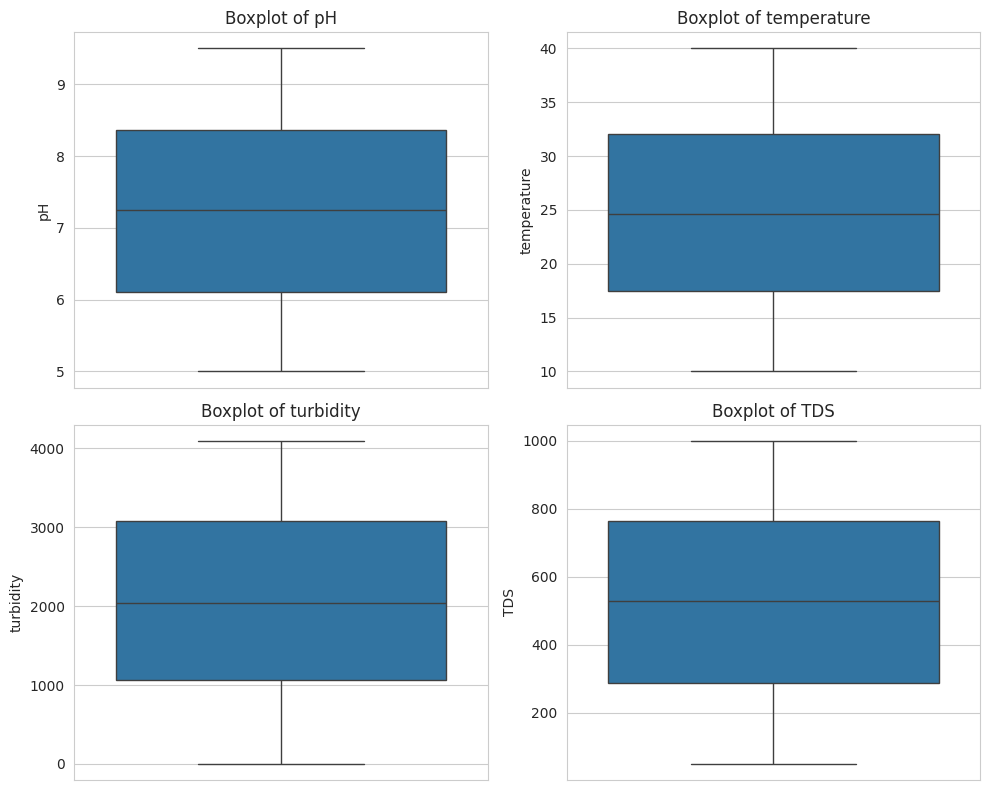

In [8]:
# 03 - feature boxplots (outlier check)
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, col in zip(axes.flatten(), FEATURE_ORDER):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/03_feature_boxplots.png", dpi=150)
plt.show()

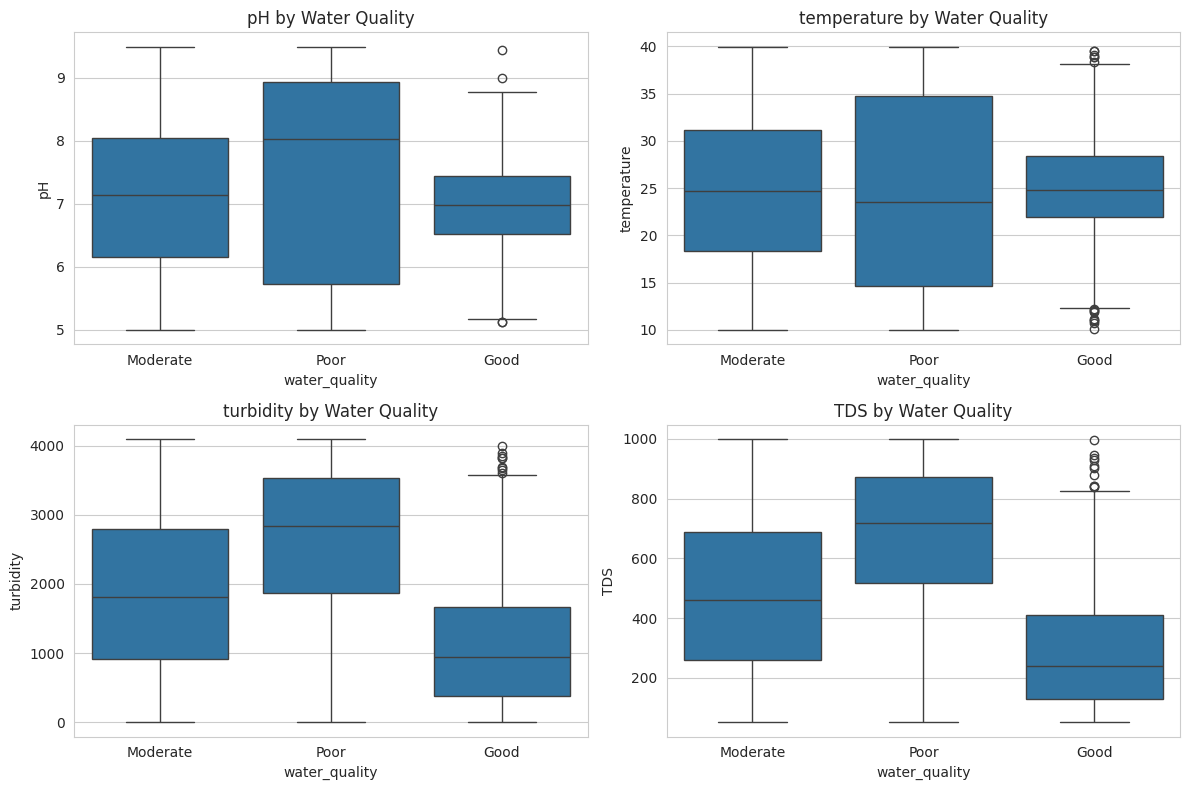

In [9]:
# 04 - features by class
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flatten(), FEATURE_ORDER):
    sns.boxplot(x=TARGET_COL, y=col, data=df, ax=ax)
    ax.set_title(f"{col} by Water Quality")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/04_features_by_class.png", dpi=150)
plt.show()

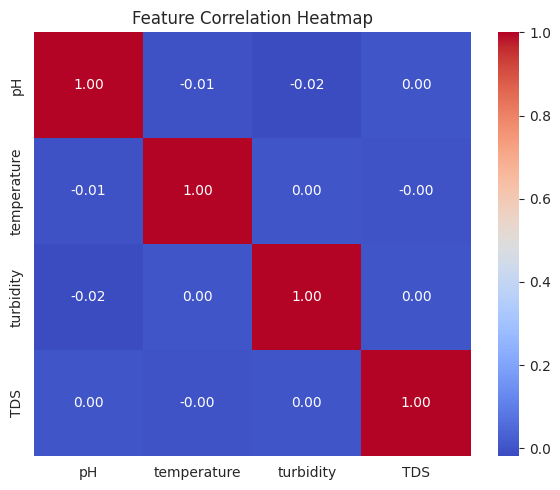

In [10]:
# 05 - correlation heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(df[FEATURE_ORDER].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/05_correlation_heatmap.png", dpi=150)
plt.show()

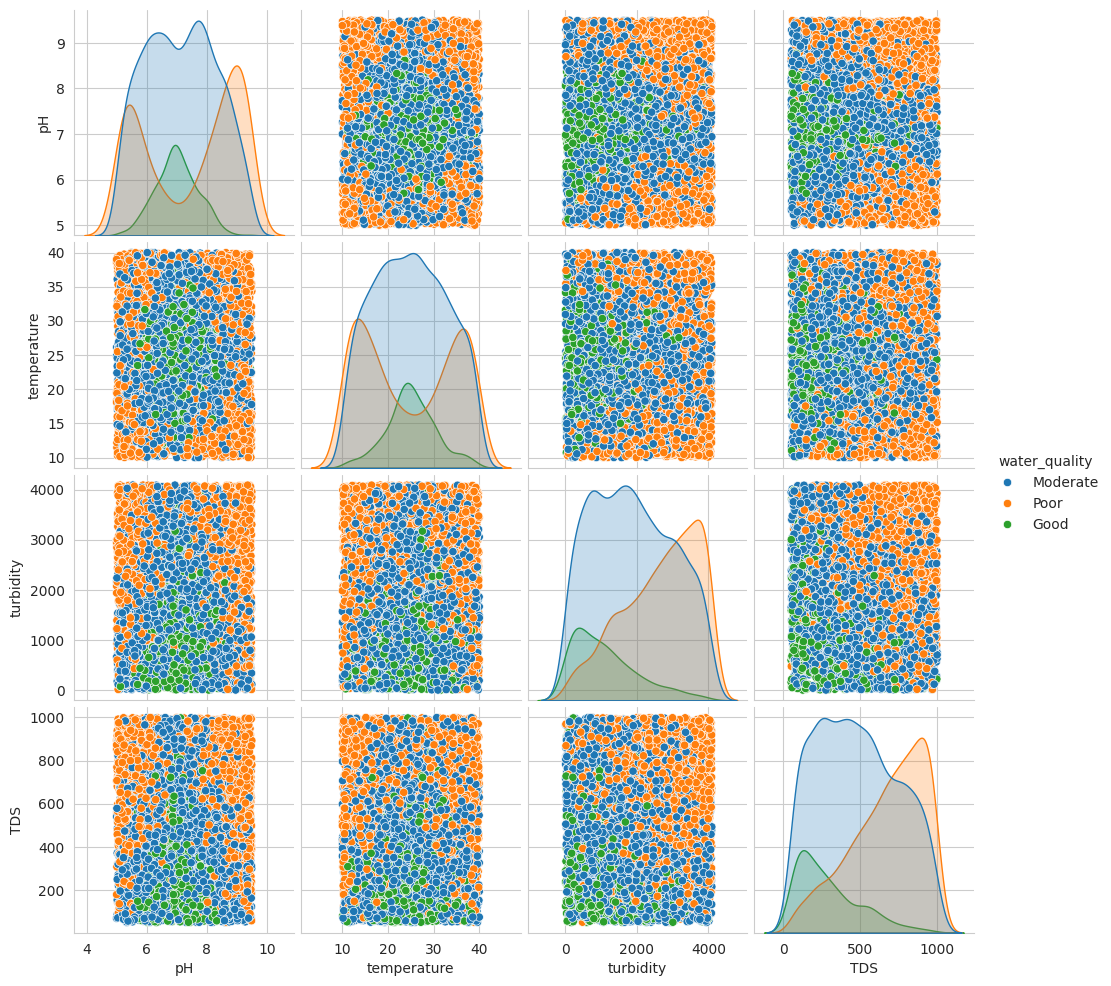

In [11]:
# 06 - pairplot
pairplot_fig = sns.pairplot(df, vars=FEATURE_ORDER, hue=TARGET_COL, diag_kind="kde")
pairplot_fig.savefig(f"{PLOTS_DIR}/06_pairplot.png", dpi=150)
plt.show()

## 3. Encode Target & Split Data

In [12]:
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df[TARGET_COL])   # Good=0, Moderate=1, Poor=2
X = df[FEATURE_ORDER]

print("Classes:", list(label_encoder.classes_))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Classes: ['Good', 'Moderate', 'Poor']
Train shape: (4000, 4), Test shape: (1000, 4)


## 4. Feature Scaling

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 5. Train & Compare Candidate Models

We train six classifiers and compare them on accuracy, precision, recall, and F1-score.

In [14]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "SVM": SVC(C=10, probability=True, random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB(),
}

results = []
trained_models = {}
confusion_matrices = {}

for name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results.append({"Model": name, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1-Score": f1})
    trained_models[name] = clf
    confusion_matrices[name] = confusion_matrix(y_test, y_pred)

    print(f"\n{name}")
    print(classification_report(y_test, y_pred, target_names=label_encoder.classes_, zero_division=0))


Logistic Regression
              precision    recall  f1-score   support

        Good       0.56      0.18      0.27       107
    Moderate       0.66      0.79      0.72       548
        Poor       0.67      0.61      0.64       345

    accuracy                           0.66      1000
   macro avg       0.63      0.53      0.54      1000
weighted avg       0.65      0.66      0.64      1000


KNN
              precision    recall  f1-score   support

        Good       0.89      0.77      0.82       107
    Moderate       0.89      0.94      0.92       548
        Poor       0.94      0.88      0.91       345

    accuracy                           0.90      1000
   macro avg       0.91      0.86      0.88      1000
weighted avg       0.90      0.90      0.90      1000


Decision Tree
              precision    recall  f1-score   support

        Good       0.71      0.65      0.68       107
    Moderate       0.83      0.86      0.85       548
        Poor       0.86      0.83 


Random Forest
              precision    recall  f1-score   support

        Good       0.95      0.65      0.77       107
    Moderate       0.87      0.93      0.90       548
        Poor       0.90      0.88      0.89       345

    accuracy                           0.88      1000
   macro avg       0.90      0.82      0.85      1000
weighted avg       0.89      0.88      0.88      1000




SVM
              precision    recall  f1-score   support

        Good       0.93      0.86      0.89       107
    Moderate       0.94      0.97      0.95       548
        Poor       0.97      0.94      0.95       345

    accuracy                           0.95      1000
   macro avg       0.95      0.92      0.93      1000
weighted avg       0.95      0.95      0.95      1000


Naive Bayes
              precision    recall  f1-score   support

        Good       1.00      0.15      0.26       107
    Moderate       0.71      0.90      0.79       548
        Poor       0.81      0.67      0.73       345

    accuracy                           0.74      1000
   macro avg       0.84      0.57      0.59      1000
weighted avg       0.77      0.74      0.71      1000



In [15]:
results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,SVM,0.947,0.947311,0.947,0.946773
1,KNN,0.904,0.904943,0.904,0.903262
2,Random Forest,0.884,0.886695,0.884,0.881932
3,Decision Tree,0.829,0.828179,0.829,0.828251
4,Naive Bayes,0.739,0.771922,0.739,0.713044
5,Logistic Regression,0.661,0.653877,0.661,0.643409


## 6. Comparison Plots

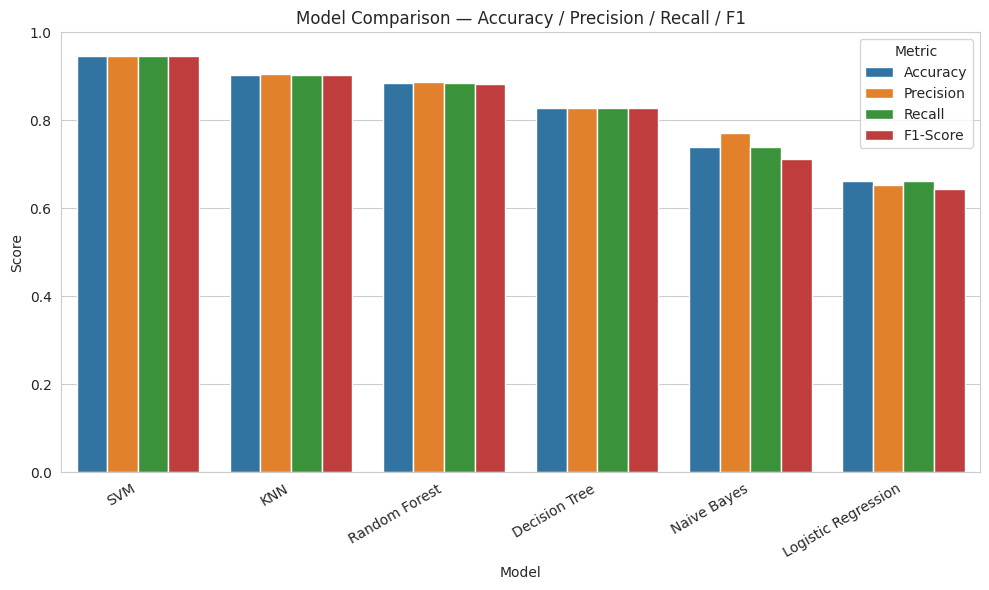

In [16]:
# 07 - metrics comparison (grouped bar chart)
metrics_melted = results_df.melt(id_vars="Model", var_name="Metric", value_name="Score")
plt.figure(figsize=(10, 6))
sns.barplot(data=metrics_melted, x="Model", y="Score", hue="Metric")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.title("Model Comparison — Accuracy / Precision / Recall / F1")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/07_model_comparison_metrics.png", dpi=150)
plt.show()

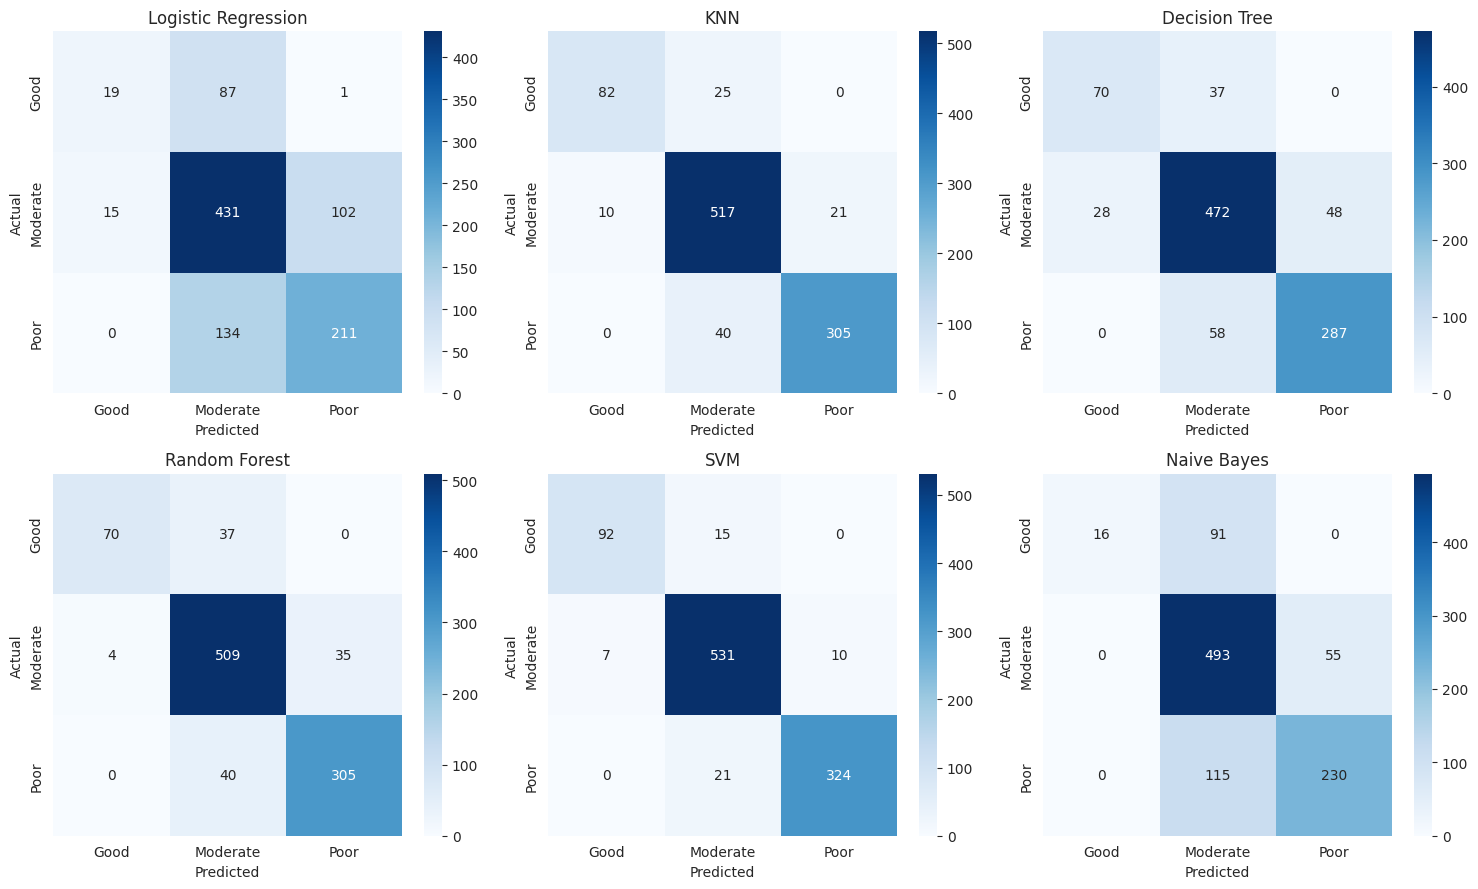

In [17]:
# 08 - confusion matrices grid
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, cm) in zip(axes.flatten(), confusion_matrices.items()):
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=label_encoder.classes_, yticklabels=label_encoder.classes_,
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/08_confusion_matrices.png", dpi=150)
plt.show()

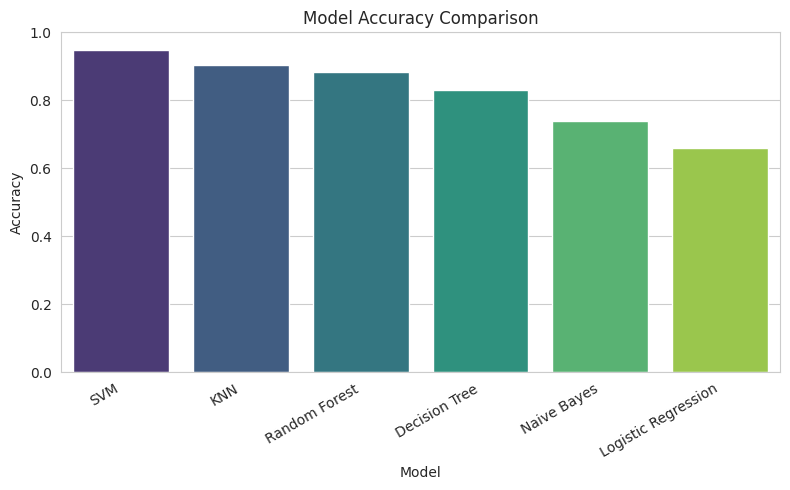

In [18]:
# 09 - accuracy comparison
plt.figure(figsize=(8, 5))
sns.barplot(data=results_df, x="Model", y="Accuracy", hue="Model", palette="viridis", legend=False)
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.title("Model Accuracy Comparison")
plt.tight_layout()
plt.savefig(f"{PLOTS_DIR}/09_accuracy_comparison.png", dpi=150)
plt.show()

## 7. Select & Save the Best Model

The best-performing model (by accuracy) is saved along with the scaler, label encoder, and feature order — matching the filenames `app.py` already loads.

In [19]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
print(f"Best model: {best_model_name} (Accuracy = {results_df.iloc[0]['Accuracy']:.4f})")

joblib.dump(best_model, f"{MODELS_DIR}/best_water_quality_model.pkl")
joblib.dump(scaler, f"{MODELS_DIR}/scaler.pkl")
joblib.dump(label_encoder, f"{MODELS_DIR}/label_encoder.pkl")
joblib.dump(FEATURE_ORDER, f"{MODELS_DIR}/feature_order.pkl")

print("\nSaved artifacts to models/:")
print("  - best_water_quality_model.pkl")
print("  - scaler.pkl")
print("  - label_encoder.pkl")
print("  - feature_order.pkl")

Best model: SVM (Accuracy = 0.9470)

Saved artifacts to models/:
  - best_water_quality_model.pkl
  - scaler.pkl
  - label_encoder.pkl
  - feature_order.pkl


## 8. Quick Sanity Check

Load the saved artifacts back and run a single prediction, the same way `app.py` does it.

In [20]:
model = joblib.load(f"{MODELS_DIR}/best_water_quality_model.pkl")
scaler_loaded = joblib.load(f"{MODELS_DIR}/scaler.pkl")
le_loaded = joblib.load(f"{MODELS_DIR}/label_encoder.pkl")
feature_order_loaded = joblib.load(f"{MODELS_DIR}/feature_order.pkl")

sample = pd.DataFrame([[7.0, 25.0, 500, 300]], columns=feature_order_loaded)
sample_scaled = scaler_loaded.transform(sample)
pred = model.predict(sample_scaled)[0]
pred_label = le_loaded.inverse_transform([pred])[0]

print("Sample input:", sample.to_dict(orient="records")[0])
print("Predicted water quality:", pred_label)

Sample input: {'pH': 7.0, 'temperature': 25.0, 'turbidity': 500, 'TDS': 300}
Predicted water quality: Good
